<a href="https://colab.research.google.com/github/mohammedelmagrii-beep/Mohamed-Ahmed-elmagry/blob/main/BRAIN_TUMOR_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics

# Paste your Roboflow download code here:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="zVK0q1p7Ks8y5jkC7HUV")
project = rf.workspace("brain-tumor-vgvlj").project("brain-tumor-8twd6")
version = project.version(1)
dataset = version.download("yolov8")

# This downloads a folder containing 'data.yaml', 'train', 'valid', and 'test'
DATA_YAML = f"{dataset.location}/data.yaml"

loading Roboflow workspace...
loading Roboflow project...


Classes: ['Tumor-Cell']

--- STEP 1 & 3: SUMMARY & MISSING VALUES ---
Total Box Annotations: 1431
Missing values in metadata:
 split        0
filename     0
class_id     0
x            0
y            0
w            0
h            0
img_w        0
img_h        0
has_tumor    0
dtype: int64




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



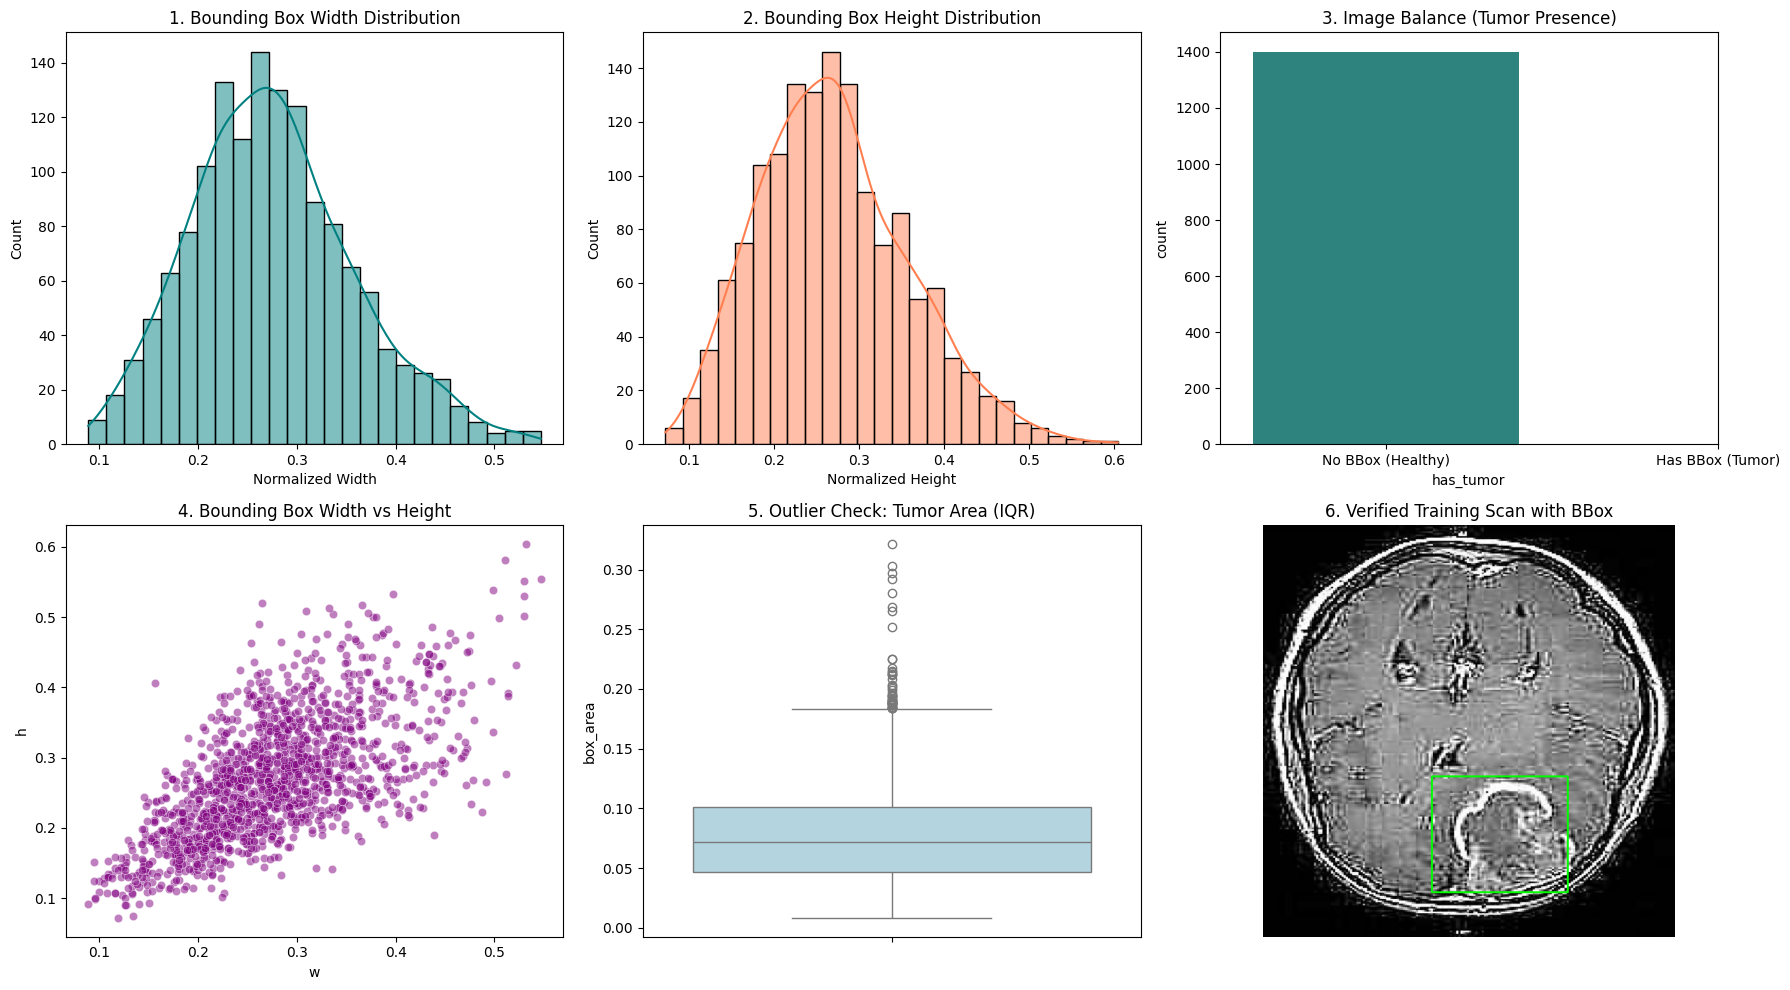

In [ ]:
import os
import glob
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Read data.yaml
with open(DATA_YAML, 'r') as f:
    data_info = yaml.safe_load(f)

classes = data_info.get('names', [])
print("Classes:", classes)

# Parse bounding box labels for exploration (Steps 1, 2, 3, 4)
records = []
splits = ['train', 'valid', 'test']

for split in splits:
    lbl_dir = os.path.join(dataset.location, split, 'labels')
    img_dir = os.path.join(dataset.location, split, 'images')
    if not os.path.exists(lbl_dir):
        continue
    for txt_file in glob.glob(f"{lbl_dir}/*.txt"):
        base_name = os.path.splitext(os.path.basename(txt_file))[0]
        # find matching image
        img_matches = glob.glob(f"{img_dir}/{base_name}.*")
        img_exists = len(img_matches) > 0
        img_w, img_h = (Image.open(img_matches[0]).size) if img_exists else (np.nan, np.nan)

        with open(txt_file, 'r') as f:
            lines = f.readlines()
            if not lines: # Background / healthy scan without tumor
                records.append({
                    "split": split, "filename": base_name, "class_id": -1,
                    "x": np.nan, "y": np.nan, "w": np.nan, "h": np.nan,
                    "img_w": img_w, "img_h": img_h, "has_tumor": 0
                })
            for line in lines:
                parts = line.strip().split()
                if len(parts) == 5:
                    records.append({
                        "split": split, "filename": base_name, "class_id": int(parts[0]),
                        "x": float(parts[1]), "y": float(parts[2]), "w": float(parts[3]), "h": float(parts[4]),
                        "img_w": img_w, "img_h": img_h, "has_tumor": 1
                    })

df = pd.DataFrame(records)

print("\n--- STEP 1 & 3: SUMMARY & MISSING VALUES ---")
print(f"Total Box Annotations: {len(df)}")
print("Missing values in metadata:\n", df.isnull().sum())

# STEP 5: 6 Visualizations Grid
plt.figure(figsize=(18, 10))

# 1. Bounding Box Width Distribution (Univariate KDE)
plt.subplot(2, 3, 1)
sns.histplot(df['w'].dropna(), kde=True, color='teal')
plt.title("1. Bounding Box Width Distribution")
plt.xlabel("Normalized Width")

# 2. Bounding Box Height Distribution (Univariate KDE)
plt.subplot(2, 3, 2)
sns.histplot(df['h'].dropna(), kde=True, color='coral')
plt.title("2. Bounding Box Height Distribution")
plt.xlabel("Normalized Height")

# 3. Tumor vs Background Balance Check (Step 6)
plt.subplot(2, 3, 3)
sns.countplot(data=df.drop_duplicates('filename'), x='has_tumor', palette='viridis')
plt.xticks([0, 1], ['No BBox (Healthy)', 'Has BBox (Tumor)'])
plt.title("3. Image Balance (Tumor Presence)")

# 4. Bivariate: Tumor Bounding Box Aspect Ratio (Width vs Height)
plt.subplot(2, 3, 4)
sns.scatterplot(data=df.dropna(), x='w', y='h', alpha=0.5, color='purple')
plt.title("4. Bounding Box Width vs Height")

# 5. Outlier Detection: Boxplot of Tumor Area (w * h)
plt.subplot(2, 3, 5)
df['box_area'] = df['w'] * df['h']
sns.boxplot(y=df['box_area'], color='lightblue')
plt.title("5. Outlier Check: Tumor Area (IQR)")

# 6. Sample Image with Bounding Box
plt.subplot(2, 3, 6)
import cv2
sample_img_path = glob.glob(f"{dataset.location}/train/images/*")[0]
sample_lbl_path = sample_img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
img_bgr = cv2.imread(sample_img_path)
h_img, w_img, _ = img_bgr.shape

if os.path.exists(sample_lbl_path):
    with open(sample_lbl_path) as f:
        for line in f.readlines():
            cls, xc, yc, bw, bh = map(float, line.strip().split())
            x1 = int((xc - bw / 2) * w_img)
            y1 = int((yc - bh / 2) * h_img)
            x2 = int((xc + bw / 2) * w_img)
            y2 = int((yc + bh / 2) * h_img)
            cv2.rectangle(img_bgr, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.title("6. Verified Training Scan with BBox")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO

# Load pre-trained lightweight YOLOv8 nano model
model = YOLO("yolov8n.pt")

# Train model for 25 epochs
results = model.train(
    data=DATA_YAML,
    epochs=18,
    imgsz=640,
    batch=16,
    plots=True,          # Generates learning curves, confusion matrix, PR curves automatically
    device=0             # Uses Colab T4 GPU
)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Brain-Tumor-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=18, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, o

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1382.1±544.7 MB/s, size: 48.7 KB)
val: Scanning /content/Brain-Tumor-1/test/labels... 140 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 140/140 2.0Kit/s 0.1s
val: New cache created: /content/Brain-Tumor-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.2it/s 4.0s
                   all        140        143       0.95      0.902      0.956      0.447
Speed: 6.6ms preprocess, 6.0ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/runs/detect/val

             YOLOv8 DETECTION METRICS
Precision:         0.9499
Recall:            0.9021
mAP@50 (IoU 0.5):   0.9555
mAP@50-95:         0.4465

Generated Validation Plots:
--- confusion_matrix.png ---


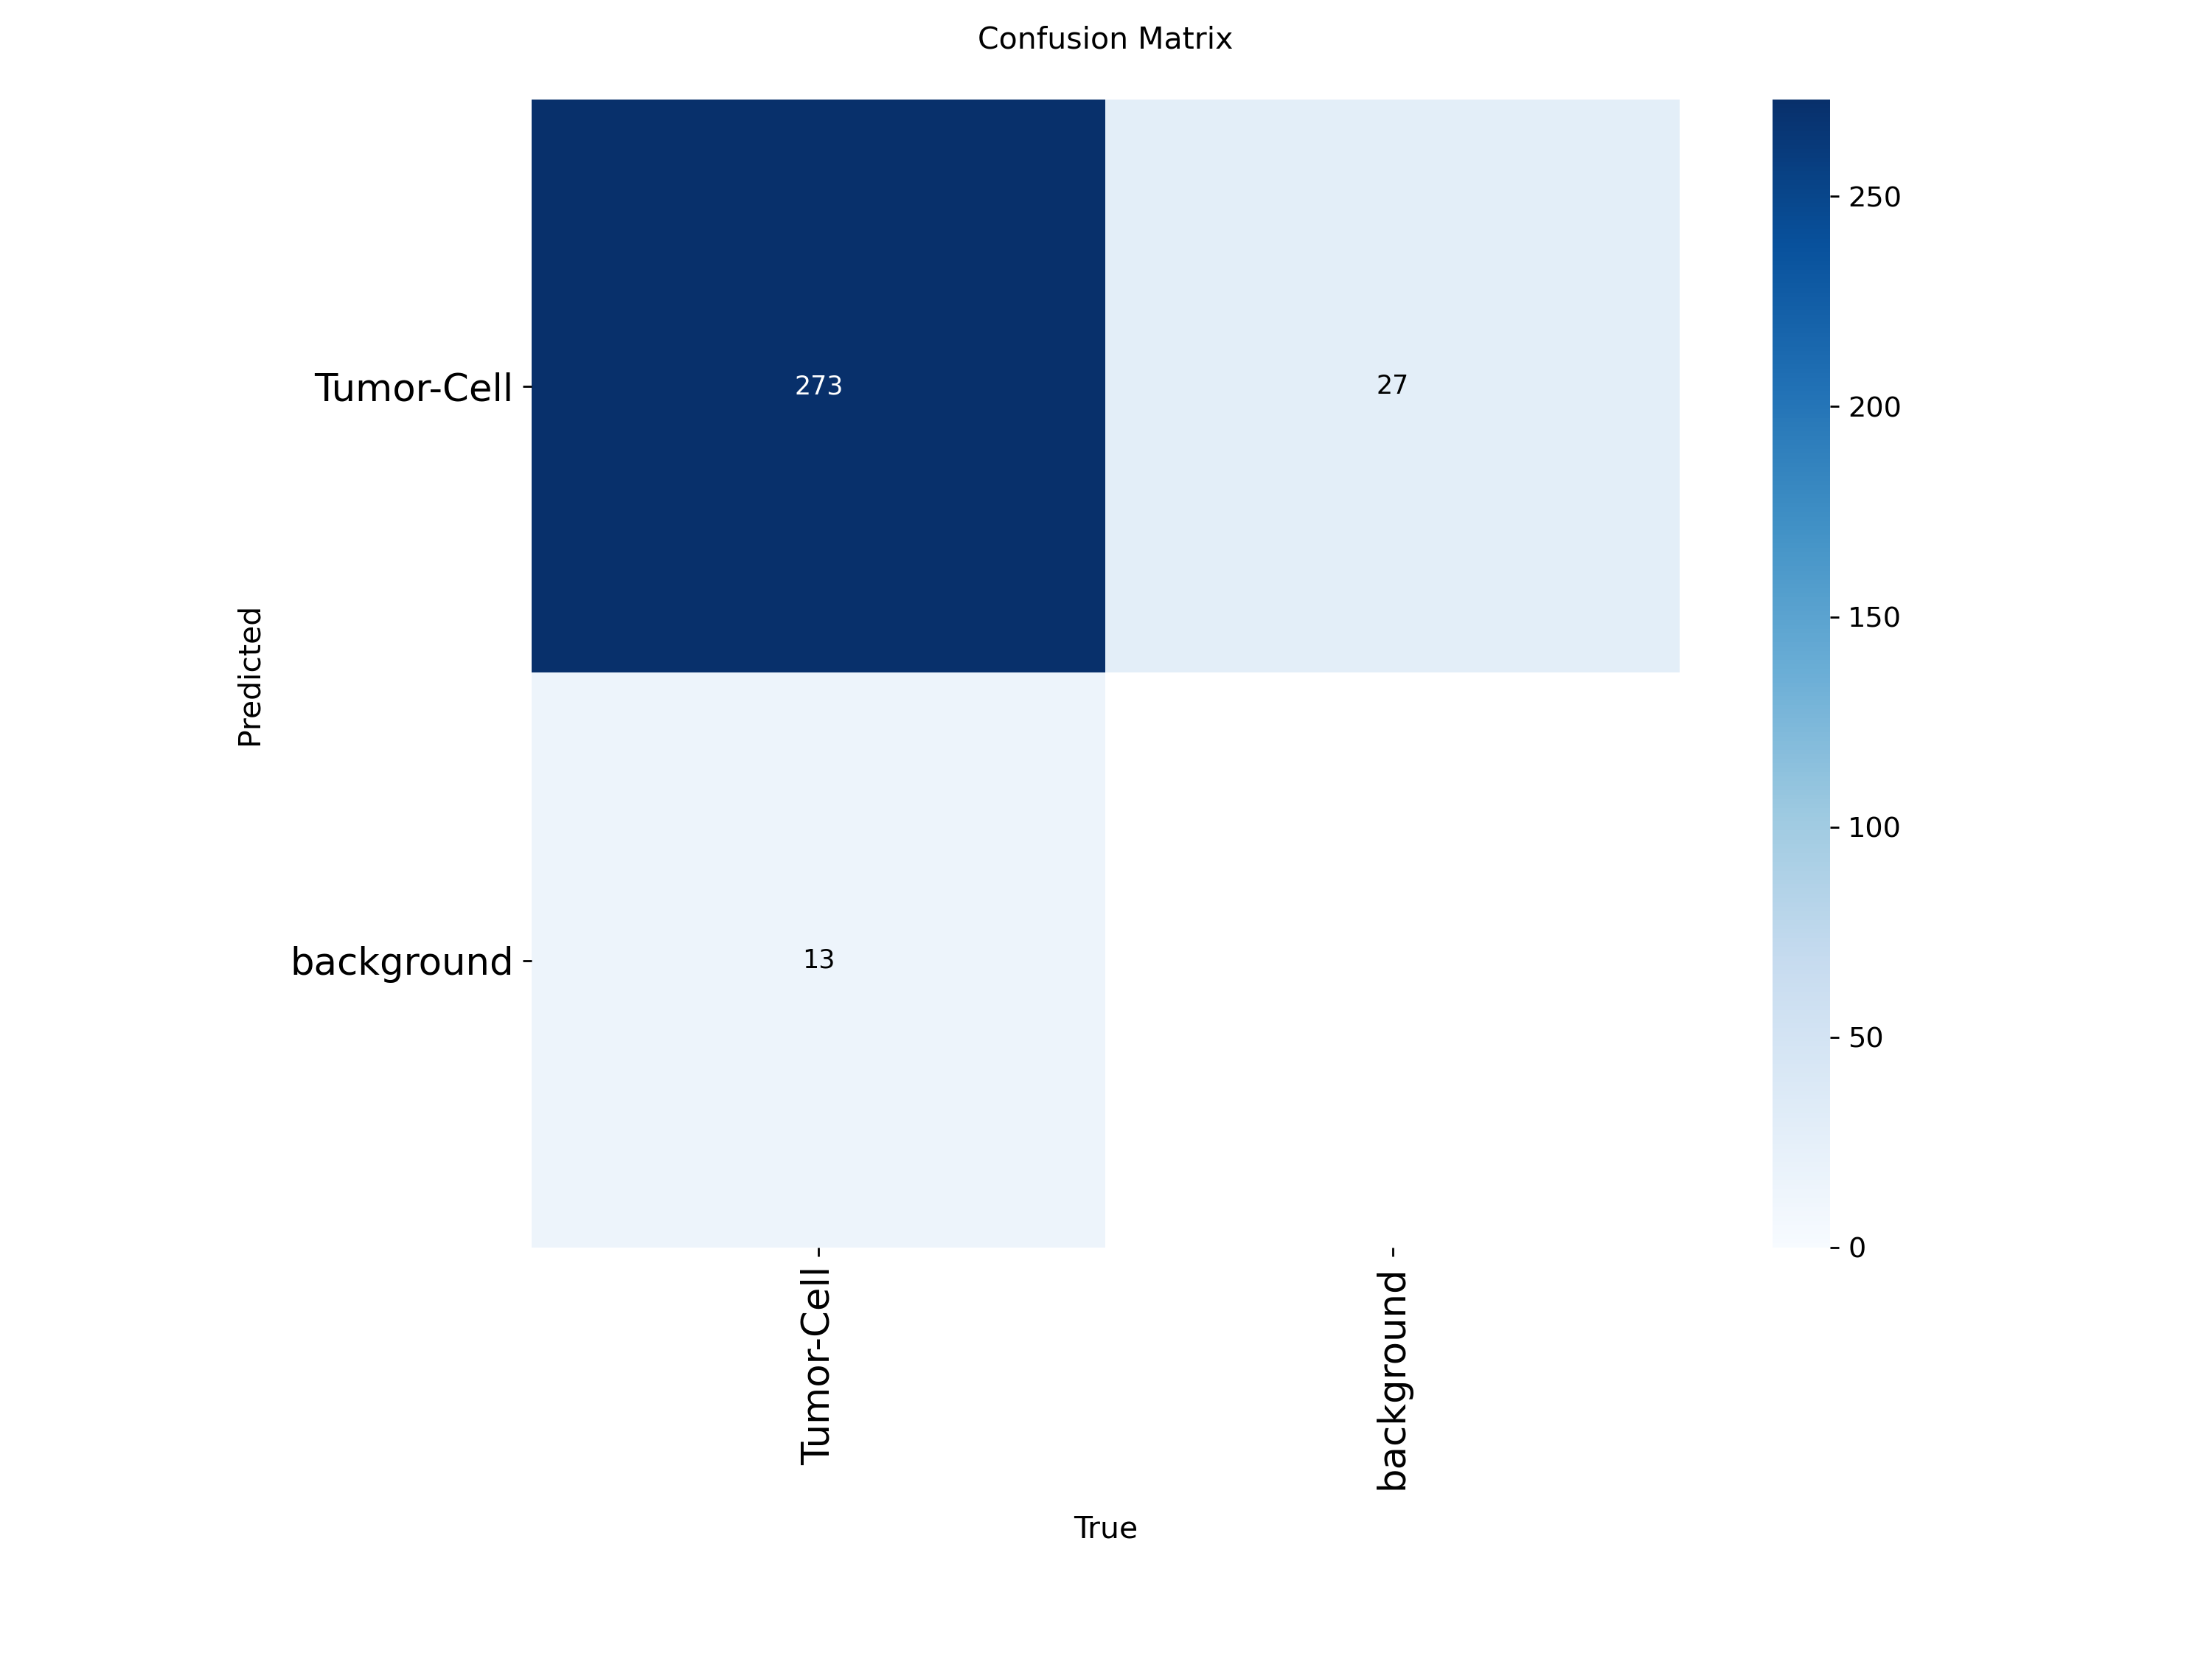

--- results.png ---


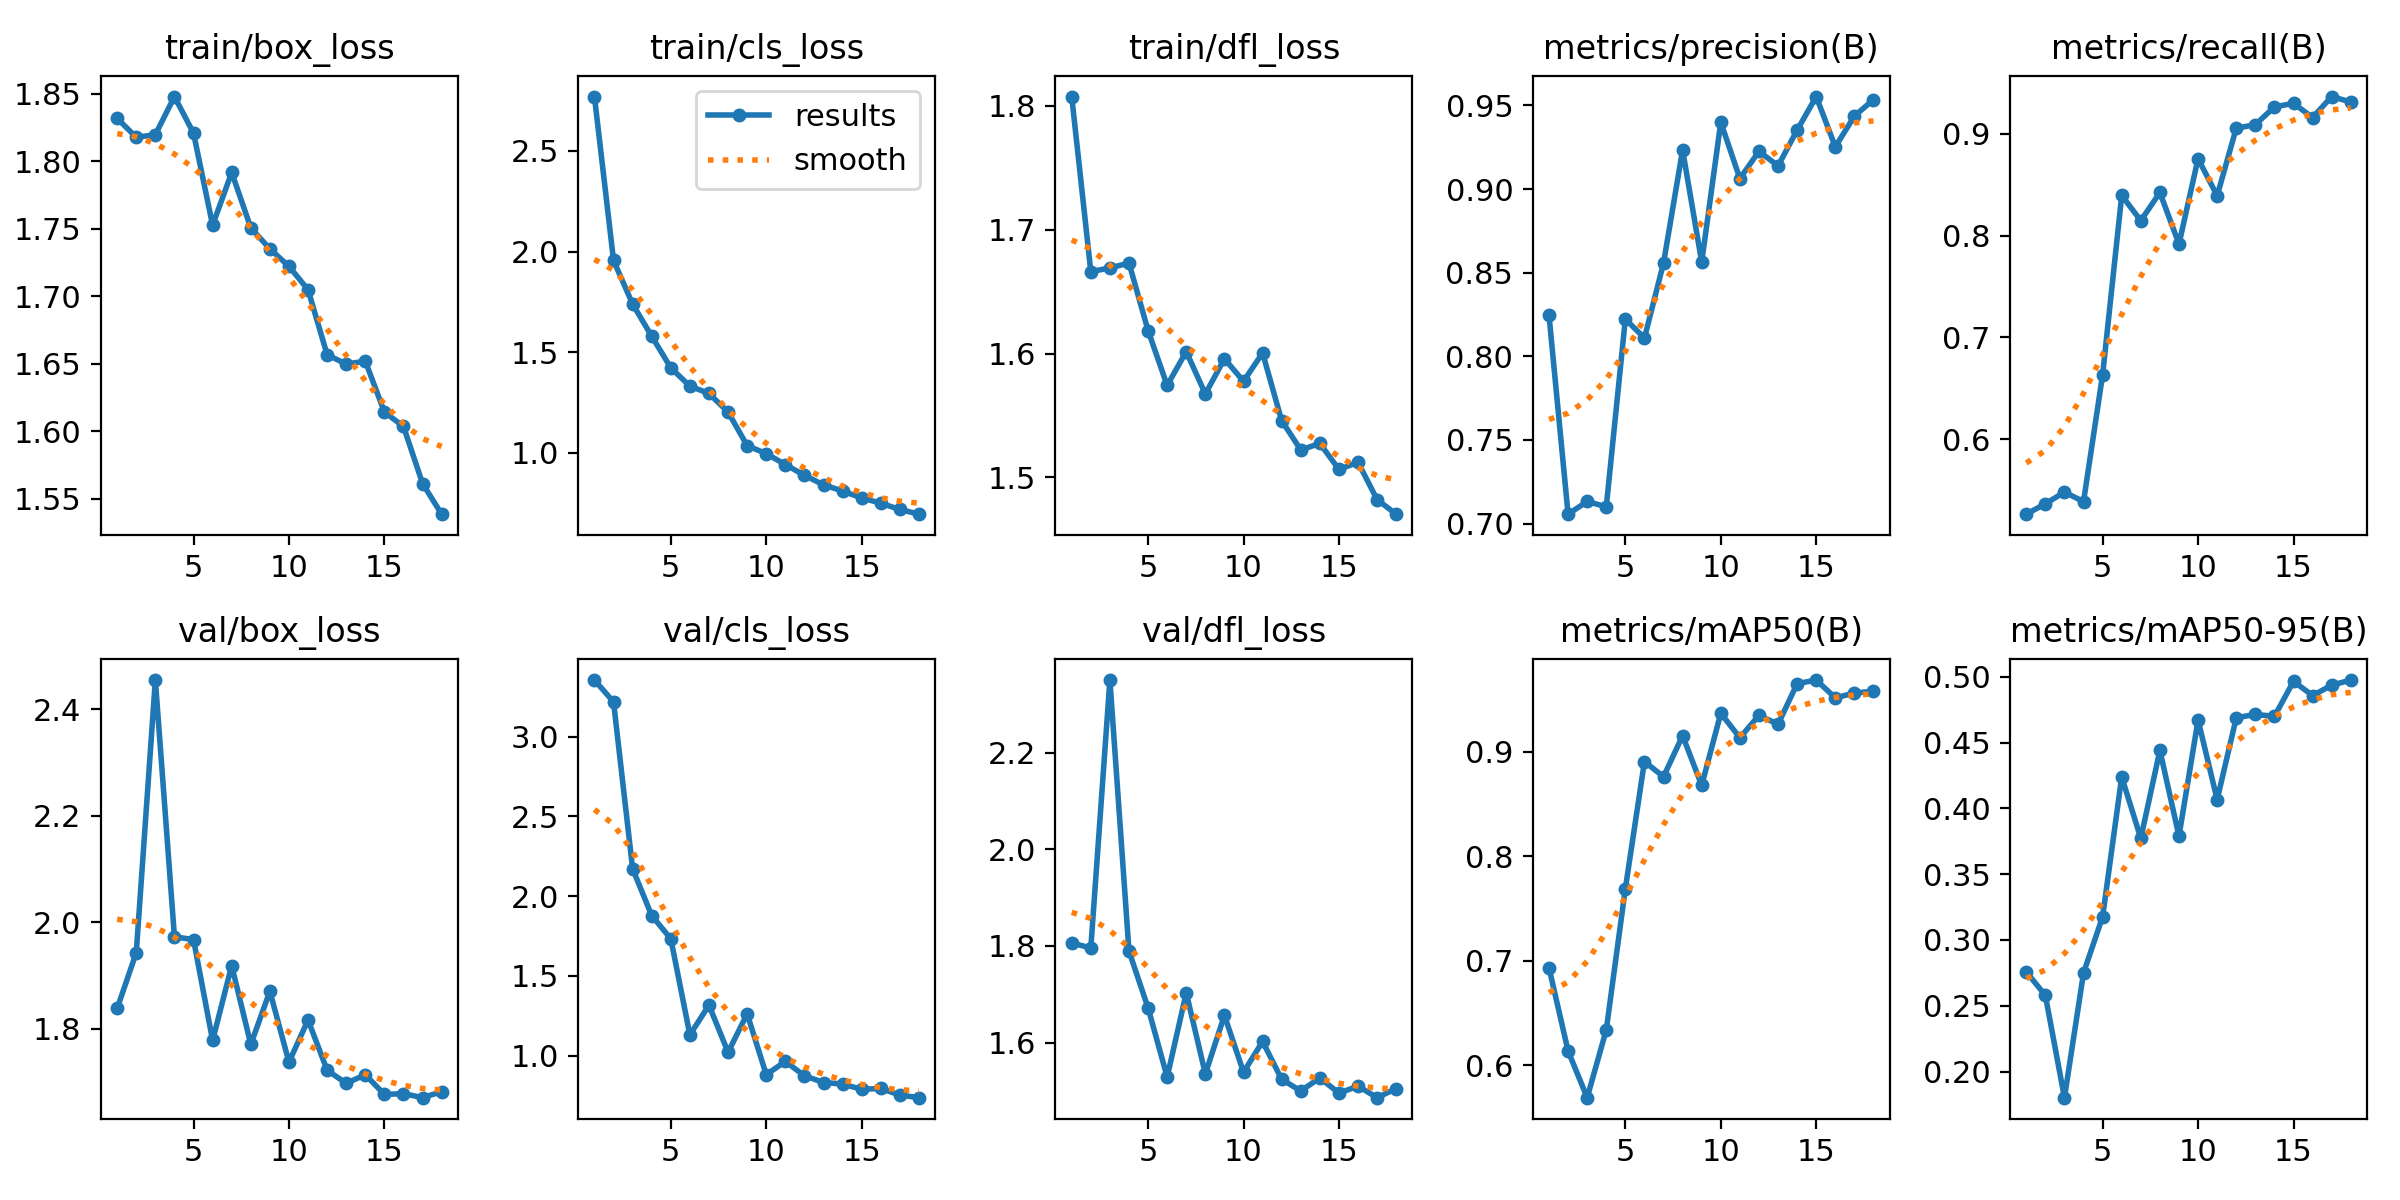

In [ ]:
# Evaluate on test split
metrics = model.val(split='test')

print("\n" + "="*50)
print("             YOLOv8 DETECTION METRICS")
print("="*50)
print(f"Precision:         {metrics.box.mp:.4f}")
print(f"Recall:            {metrics.box.mr:.4f}")
print(f"mAP@50 (IoU 0.5):   {metrics.box.map50:.4f}")
print(f"mAP@50-95:         {metrics.box.map:.4f}")
print("="*50)

# Display Ultralytics auto-generated plots (Confusion matrix & PR curves)
from IPython.display import Image as ShowImage, display

save_dir = results.save_dir
print("\nGenerated Validation Plots:")
for plot_name in ['confusion_matrix.png', 'results.png', 'PR_curve.png']:
    p = os.path.join(save_dir, plot_name)
    if os.path.exists(p):
        print(f"--- {plot_name} ---")
        display(ShowImage(p))


image 1/1 /content/Brain-Tumor-1/test/images/y991_jpg.rf.167248b90969577cd7ed45b4a435707c.jpg: 640x640 1 Tumor-Cell, 7.1ms
Speed: 1.0ms preprocess, 7.1ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


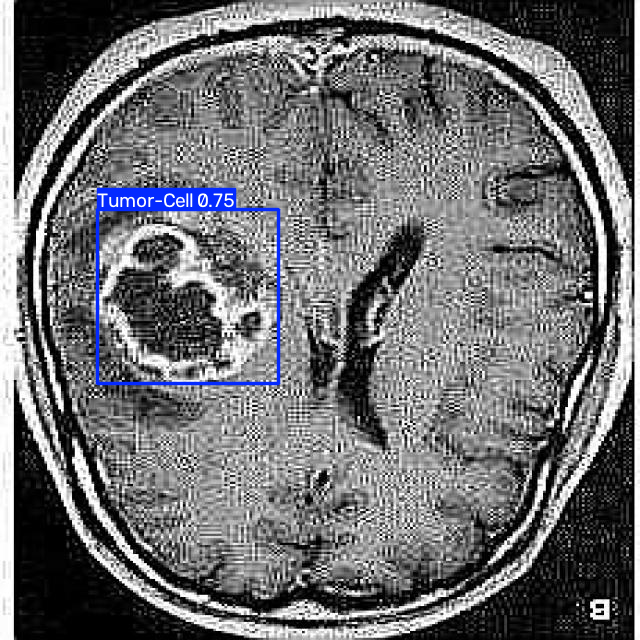

In [ ]:
# Run detection on test images and display the bounding box prediction
test_images = glob.glob(f"{dataset.location}/test/images/*")
sample_test = test_images[101]

res = model.predict(sample_test, conf=0.25)
res[0].show()  # Shows image with predicted bounding box and confidence score

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt
import cv2

# 1. Upload an external image from your computer
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nRunning YOLOv8 detection on: {filename}")

    # 2. Run inference with your trained model (conf threshold = 25%)
    results = model.predict(source=filename, conf=0.25)
    res = results[0]

    # 3. Print detected bounding boxes and confidences
    boxes = res.boxes
    if len(boxes) == 0:
        print("Result: No tumor detected (Scan is Healthy / Background).")
    else:
        print(f"Result: Detected {len(boxes)} potential tumor region(s)!")
        for i, box in enumerate(boxes):
            conf = float(box.conf[0]) * 100
            cls_id = int(box.cls[0])
            cls_name = model.names[cls_id]
            xyxy = box.xyxy[0].tolist()  # [x1, y1, x2, y2]
            print(f" - Region {i+1} [{cls_name}]: Confidence = {conf:.2f}% | Box coordinates = {[round(x, 1) for x in xyxy]}")

    # 4. Display the image with the predicted bounding box overlay
    rendered_img = res.plot()  # Draws the bounding boxes and confidence labels

    plt.figure(figsize=(7, 7))
    plt.imshow(cv2.cvtColor(rendered_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Prediction: {filename}")
    plt.axis("off")
    plt.show()